## Module 2: FSHD Clinical Trial Project

## Project Goal:

Our Biomarkers and Clinical Outcomes team has been tasked to design an early-stage clinical trial for a new Facioscapulohumeral Muscular Dystrophy (FSHD) treatment. We are analyzing natural-history data from 34 patients in a longitudinal study over 2 years to determine which measures should be used in the clinical trial as exploratory endpoints. There has been much debate within the field as to which measures best represent the progression of the disease over time. FSHD affects patients across several realms—not only biologically, but in terms of physical function, mobility, and overall quality of life. By the end of our investigation we hope to answer the question: 

Over about two years, does MRI fat fraction of the tibialis anterior change more consistently than 10-meter walk/run time in FSHD patients, and do changes in the two measures track each other?



## Disease Background: 

Facioscapulohumeral muscular dystrophy (FSHD) is a rare genetic disease that causes the degeneration of skeletal muscles. In particular, muscle weakness most commonly begins in the face (facio), shoulders (scapula), and upper arms (humerus), but can eventually affect any muscle in the body. It is estimated that around 1 in 8,000 individuals, or 870,000 people worldwide are affected by this disease. While around 70% of cases are inherited from an affected parent, the remaining 30% arise from spontaneous genetic mutations in individuals with no prior family history of FSHD (FSHD Society, 2025). Both types of FSHD, FSHD1 and FSHD2, involve the abnormal expression of the toxic protein DUX4. In FSHD1 and FSHD2, the loss of D4Z4 repeats and demethylation of the DNA allows for the epigenetic derepression and sequential translation of the protein. This protein is toxic to muscle cells, and leads to their eventual degradation and death (Statland & Tawil, 2016). FSHD symptoms vary widely in terms of onset, presentation, and severity. 10 percent of individuals show symptoms before the age of 10. Most commonly, it presents anywhere from the ages of 15-30, though symptoms can onset at any age. Classic signs include the weakening of facial muscles, with the loss of ability to fully close the eyes, purse the lips, or turn the corners of the mouth “up” into a smile being characteristic signs. The degradation of certain muscle groups eventually severely affects mobility, with 20% of people with FSHD needing wheelchairs before 50 (FSHD Society, 2025). FSHD diagnosis typically involves a clinical evaluation, family history check, and genetic testing to confirm the condition. Those with early-onset FSHD may need specialized treatment with mobility aids, and are at a higher risk for vision or hearing problems. Managing FSHD focuses on alleviating symptoms, maximizing quality of life, and maintaining mobility and physical function. The disease progression is unique from person to person, with some that progress severely and rapidly, and others who experience a slow but gradual decline. As of now, there is no effective treatment or cure for FSHD. However, the field of FSHD research is vast, and many clinical trials aim to epigenetically enhance the repression of the D4Z4 gene, target the DUX4 mRNA, and inhibit or block the activity of DUX4. The FSHD community holds great hope for clinical research to advance treatment options and eventually lead to a cure (Wang, Tawil, & Bonne, 2021). 

## Data Set:

This project uses MRI data of the tibialis anterior (TA), the muscle on the front of the lower leg that lifts the foot. The data come from the Wellstone Muscular Dystrophy Cooperative Research Center study of FSHD, which enrolled 34 people (16 female and 18 male) aged 21 to 69 (Wong et al., 2024). We analyzed one subject, UW_0020, at two visits, TP1 and TP2. Each visit has 8 slices (cross-sections of the leg) spaced from 10% to 80% of the way along the muscle. The file slice_info.csv lists each slice’s position as a percent and as a distance in millimeters from the start of the muscle. Each slice has three NumPy files a water image, a fat image, and a mask. The water and fat images come from a Dixon MRI scan, which separates the signal from water and the signal from fat. Brighter pixels mean more of that tissue. Both images are in arbitrary signal units, so the numbers only have meaning when compared with each other, and we use them to calculate fat fraction as a percent. The mask marks which pixels are TA muscle. In the study, the TA was outlined by an AI program from Springbok Analytics and then checked by hand (Wong et al., 2024). We were given the finished masks. The full study also collected strength, a clinical severity score, a STIR inflammation rating, and biopsy gene data, but our files contain only the MRI slices.

## MRI Data Analysis Methdology:

This analysis reproduces how one MRI dataset was generated, using one subject (UW_0020) at two visits (TP1 and TP2). Each visit has eight cross-sectional slices along the tibialis anterior (TA), each with a water image, a fat image, and a muscle mask. We load the files, use the mask to isolate the TA, calculate fat fraction, summarize it, and compare locations and visits.

We load the packages and read slice_info.csv into a table called manifest. Each of its 16 rows is one slice (8 per visit) and lists the slice’s location along the muscle and the names of its water, fat, and mask files.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2")
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest

,subject,timepoint,slice_id,percent_along_muscle,z_index,distance_from_muscle_start_mm,water_file,fat_file,mask_file
0,UW_0020,TP1,1,10,41,24.0,TP1_slice_01_water.npy,TP1_slice_01_fat.npy,TP1_slice_01_mask.npy
1,UW_0020,TP1,2,20,46,44.0,TP1_slice_02_water.npy,TP1_slice_02_fat.npy,TP1_slice_02_mask.npy
2,UW_0020,TP1,3,30,52,68.0,TP1_slice_03_water.npy,TP1_slice_03_fat.npy,TP1_slice_03_mask.npy
3,UW_0020,TP1,4,40,58,92.0,TP1_slice_04_water.npy,TP1_slice_04_fat.npy,TP1_slice_04_mask.npy
4,UW_0020,TP1,5,50,64,116.0,TP1_slice_05_water.npy,TP1_slice_05_fat.npy,TP1_slice_05_mask.npy
5,UW_0020,TP1,6,60,69,136.0,TP1_slice_06_water.npy,TP1_slice_06_fat.npy,TP1_slice_06_mask.npy
6,UW_0020,TP1,7,70,75,160.0,TP1_slice_07_water.npy,TP1_slice_07_fat.npy,TP1_slice_07_mask.npy
7,UW_0020,TP1,8,80,81,184.0,TP1_slice_08_water.npy,TP1_slice_08_fat.npy,TP1_slice_08_mask.npy
8,UW_0020,TP2,1,10,40,24.0,TP2_slice_01_water.npy,TP2_slice_01_fat.npy,TP2_slice_01_mask.npy
9,UW_0020,TP2,2,20,46,48.0,TP2_slice_02_water.npy,TP2_slice_02_fat.npy,TP2_slice_02_mask.npy


We load the water image, fat image, and mask for one TP1 slice, slice 04, which is 40% along the muscle. The mask is converted so that each pixel is either muscle (true) or not muscle (false). All three images are 266 × 224 pixels, so they line up pixel for pixel. The mask contains 360 muscle pixels.

In [3]:
row = manifest[manifest["timepoint"] == "TP1"].iloc[3]  # representative mid-muscle slice

water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360


Fat fraction is fat signal divided by (water signal + fat signal), times 100. Pixels where the total is zero are set to 0 so we never divide by zero. We calculate it for the whole image region and for the TA only, where pixels outside the mask are set to NaN so they are ignored. For slice 04, the mean fat fraction is 48.6% for the whole region and 29.9% for the TA only (range 0.5% to 90.7%).

In [4]:
denominator = water + fat
valid_pixels = denominator > 0

fat_fraction = np.divide(
    fat,
    denominator,
    out=np.zeros_like(fat, dtype=float),
    where=valid_pixels
) * 100

# Keep the whole supplied image region for the first analysis.
fat_fraction_full = fat_fraction.copy()

# Then apply the TA mask for the muscle-specific analysis.
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~mask] = np.nan

whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

print(f"Whole supplied image region — mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region — minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region — maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only — mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only — minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only — maximum: {np.max(muscle_values):.1f}%")


Whole supplied image region — mean: 48.6%
Whole supplied image region — minimum: 0.0%
Whole supplied image region — maximum: 100.0%

TA muscle only — mean: 29.9%
TA muscle only — minimum: 0.5%
TA muscle only — maximum: 90.7%


We generate Figure 1 which will show the water image, the fat image, the whole-region fat fraction, and a zoomed TA-only fat fraction map. The mask outline lets us check that it sits on the TA. Both fat fraction maps use the same 0 to 100% color scale.

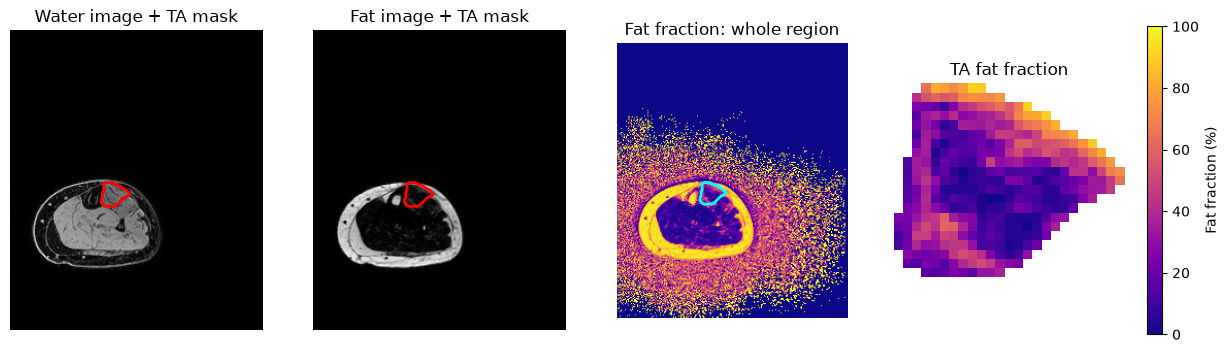

In [5]:
# Find the bounding box of the TA mask
y_pixels, x_pixels = np.where(mask)

y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1

# Crop the TA-specific fat-fraction map
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Water image with TA mask outline
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[0].set_title("Water image + TA mask")

# Fat image with TA mask outline
axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

# Fat fraction for the whole supplied image region
whole_image = axes[2].imshow(
    fat_fraction_full,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

# Zoomed-in fat fraction for the TA only
ta_image = axes[3].imshow(
    fat_fraction_TA,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[3].set_title("TA fat fraction")

for ax in axes:
    ax.axis("off")

# Both fat-fraction plots use the same 0–100% scale
fig.colorbar(
    ta_image,
    ax=axes[2:],
    fraction=0.046,
    pad=0.04,
    label="Fat fraction (%)"
)

plt.show()

Figure 1. Water image, fat image, whole-region fat fraction, and TA-only fat fraction for TP1 slice 04 (40% along the muscle). The outline marks the TA mask. This figure shows that the mask picks out the muscle from the rest of the leg. We can conclude that the mask sits on the TA, and that fat fraction inside the muscle is mostly low to moderate, with higher values along its upper edge.

Now, Figure 2 will show histograms of fat fraction for the whole region and for the TA only, so we can see how the values are spread out and not just their average.

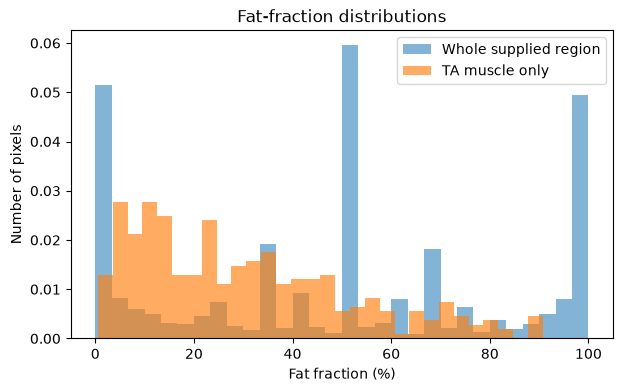

In [6]:
plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=30, alpha=0.55, label="Whole supplied region", density=True)
plt.hist(muscle_values, bins=30, alpha=0.65, label="TA muscle only", density=True)
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distributions")
plt.legend()
plt.show()


Figure 2. Histograms of fat fraction (%) for the whole supplied region and the TA only, for TP1 slice 04. The whole region has large peaks near 0%, 50%, and 100% because it includes air, noise, subcutaneous fat, and other tissue. The TA-only values have a median of 25.4% and a mean of 29.9%, which means most pixels have lower fat but a tail of high-fat pixels pulls the mean up. This figure shows why the mask is needed, since whole-region values do not describe the muscle.

We put the fat fraction calculation into a function and loop through all 8 TP1 slices. For each slice we record the mean, median, standard deviation, and number of muscle pixels, along with its location. The pixel count shows whether the muscle area changed, and the median is less affected by a few very fatty pixels.

In [7]:
def calculate_fat_fraction(water, fat, mask):
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(
        fat,
        denominator,
        out=np.zeros_like(fat, dtype=float),
        where=denominator > 0
    ) * 100
    result[~mask] = np.nan
    return result

analysis_timepoint = "TP1"  # analyze one visit at a time
analysis_manifest = manifest[manifest["timepoint"] == analysis_timepoint]
results = []

for _, row in analysis_manifest.iterrows():
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)

    results.append({
        "subject": row["subject"],
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "percent_along_muscle": row["percent_along_muscle"],
        "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
    })

results_df = pd.DataFrame(results)
results_df


,subject,timepoint,slice_id,percent_along_muscle,distance_from_muscle_start_mm,mean_fat_fraction_percent,median_fat_fraction_percent,std_fat_fraction_percent,n_muscle_pixels
0,UW_0020,TP1,1,10,24.0,83.924382,88.827837,13.272006,61
1,UW_0020,TP1,2,20,44.0,82.706905,86.651582,12.433905,115
2,UW_0020,TP1,3,30,68.0,58.498513,61.821705,22.878862,231
3,UW_0020,TP1,4,40,92.0,29.931733,25.369646,21.584495,360
4,UW_0020,TP1,5,50,116.0,20.866866,14.553991,20.060150,421
5,UW_0020,TP1,6,60,136.0,16.758732,9.049959,19.665424,440
6,UW_0020,TP1,7,70,160.0,17.511838,8.962264,20.456168,388
7,UW_0020,TP1,8,80,184.0,27.873337,22.685185,22.625359,263


Table 1. Muscle-only fat fraction for each TP1 slice. Mean fat fraction is highest at the start of the muscle (83.9% at 24 mm) and lowest in the middle (16.8% at 136 mm). It rises again at the far end (27.9% at 184 mm). The median is lower than the mean in the middle slices (for example 25.4% vs 29.9% at 92 mm), which means a few very fatty pixels pull the mean up. The slices at 24 mm and 44 mm contain the fewest muscle pixels (61 and 115), so their values come from a small area.

We repeat the calculation for TP2 and plot mean TA fat fraction against location for both visits. We assume slices at the same percent position are at about the same part of the muscle at both visits. The distances in millimeters differ slightly between visits (TP1 ends at 184 mm and TP2 at 196 mm), so this is only approximate.

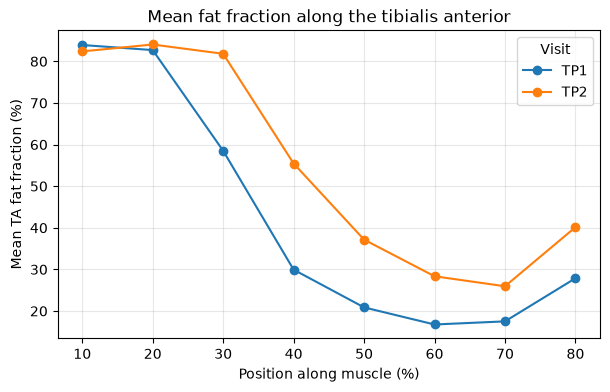

In [8]:
def summarize_visit(timepoint):
    visit_results = []
    visit_manifest = manifest[manifest["timepoint"] == timepoint]

    for _, row in visit_manifest.iterrows():
        water = np.load(DATA_DIR / row["water_file"])
        fat = np.load(DATA_DIR / row["fat_file"])
        mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
        ff = calculate_fat_fraction(water, fat, mask)

        visit_results.append({
            "timepoint": timepoint,
            "slice_id": row["slice_id"],
            "percent_along_muscle": row["percent_along_muscle"],
            "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
            "mean_fat_fraction_percent": np.nanmean(ff),
        })

    return pd.DataFrame(visit_results)

profiles_df = pd.concat(
    [summarize_visit("TP1"), summarize_visit("TP2")],
    ignore_index=True
)

plt.figure(figsize=(7, 4))
for timepoint, group in profiles_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")
    plt.plot(
        group["percent_along_muscle"],
        group["mean_fat_fraction_percent"],
        marker="o",
        label=timepoint
    )
plt.xlabel("Position along muscle (%)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()


This figure shows how fat is spread along the muscle and whether it changed between visits. Both visits show the same pattern: fat is highest near the start of the muscle and lowest in the middle. Fat fraction is similar at the first two locations but higher at TP2 from about 30% onward (roughly 55% vs 30% at 40%). We can conclude that fat increased between visits, mostly in the middle and far parts of the muscle. This is a change in muscle composition and does not by itself show a change in patient function.

## Interpolation and Data Analysis: 


In [12]:
from scipy.interpolate import interp1d
from scipy import stats
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

path = 'DataSet/Module2_FSHD_Dataset.csv'
df = pd.read_csv(path)

# Keep complete three-visit patients
cols = ['lag_months_y1', 'lag_months_y2',
        'ff_baseline_R', 'ff_y1_R', 'ff_y2_R',
        'ff_baseline_L', 'ff_y1_L', 'ff_y2_L',
        'wr_10_baseline', 'wr_10_y1', 'wr_10_y2']
df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')
df = df.dropna(subset=cols).copy()
df = df[(df.lag_months_y1 > 0) &
        (df.lag_months_y2 > df.lag_months_y1)]
df = df[(df.ff_baseline_R > 0) & (df.ff_baseline_L > 0) &
        (df.wr_10_baseline > 0)].copy()

T1, T2 = df.lag_months_y1.min(), df.lag_months_y2.min()

# Interpolate each patient's measurements
def interp(row, col, t):
    side = col[-1] if col.startswith('ff_') else None

    if side:
        times = [0, row['lag_months_y1'], row['lag_months_y2']]
        vals = [
            row[f'ff_baseline_{side}'],
            row[f'ff_y1_{side}'],
            row[f'ff_y2_{side}']
        ]
    else:
        times = [0, row['lag_months_y1'], row['lag_months_y2']]
        vals = [
            row['wr_10_baseline'],
            row['wr_10_y1'],
            row['wr_10_y2']
        ]

    return float(interp1d(times, vals)(t))

# Individual percent changes from baseline
for side in ['R', 'L']:
    for label, t in [('T1', T1), ('T2', T2)]:
        df[f'ff_{label}_{side}'] = df.apply(
            lambda r: interp(r, f'ff_{side}', t), axis=1
        )

for label, t in [('T1', T1), ('T2', T2)]:
    df[f'wr_10_{label}'] = df.apply(
        lambda r: interp(r, 'wr_10', t), axis=1
    )

df['tug_time_T2'] = df.apply(
    lambda r: interp(r, 'tug_time', T2), axis=1
)



The distances to identify the location of the muscle slice for fat fraction analysis in the MRI were determined in length (mm). These slicing points remained consistent across time. We interpolated time of return visits for each patient so the progression of the disease could be compared against homogenous intervals. We used each biomarker or functional test score at baseline, and interpolated those points at Y1: 11.15 months, and Y2: 22.13 months. Linear interpolation was used with SciPy which estimates a value between two data points by connecting them with a straight line. This interpolated point is only an estimate because we are assuming that the data progresses perfectly linearly, which is not necessarily the case. 

R T1 change vs baseline: TtestResult(statistic=np.float64(2.2500242293270367), pvalue=np.float64(0.03431406154391581), df=np.int64(23))
R T2 change vs baseline: TtestResult(statistic=np.float64(3.715104581349313), pvalue=np.float64(0.0011381881977357597), df=np.int64(23))
R T1 vs T2: TtestResult(statistic=np.float64(-1.8716965098113767), pvalue=np.float64(0.07402128580157158), df=np.int64(23))
L T1 change vs baseline: TtestResult(statistic=np.float64(4.406494581566478), pvalue=np.float64(0.00020439307916759455), df=np.int64(23))
L T2 change vs baseline: TtestResult(statistic=np.float64(3.541573179889707), pvalue=np.float64(0.0017420665437687314), df=np.int64(23))
L T1 vs T2: TtestResult(statistic=np.float64(-1.0676749857115042), pvalue=np.float64(0.29674601064165373), df=np.int64(23))

R side, T1
N = 24
Equation: y = -0.0359x + 4.1194
R-squared = 0.0032
Slope p-value = 0.7914
Pearson r = -0.0570


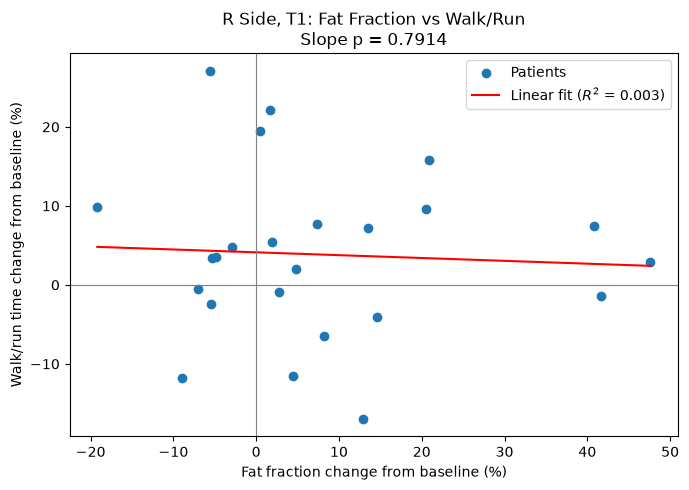


R side, T2
N = 24
Equation: y = 0.0837x + 3.8303
R-squared = 0.0131
Slope p-value = 0.5937
Pearson r = 0.1147


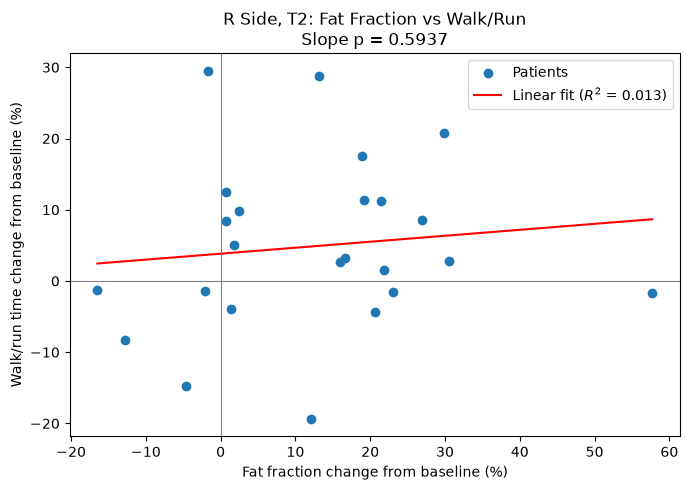


L side, T1
N = 24
Equation: y = -0.2125x + 6.0705
R-squared = 0.0549
Slope p-value = 0.2707
Pearson r = -0.2342


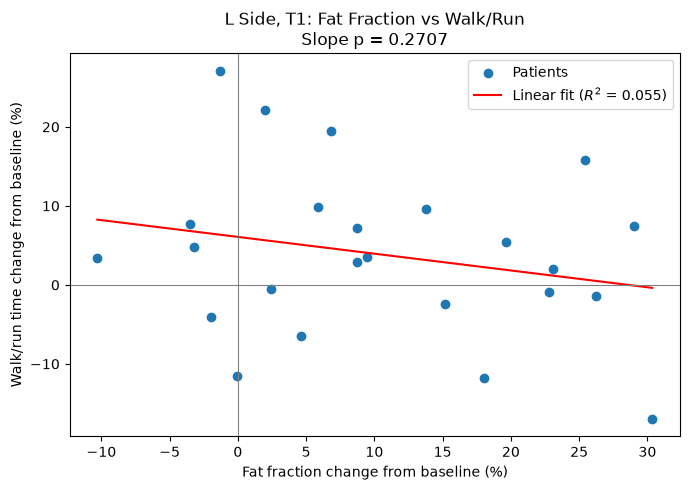


L side, T2
N = 24
Equation: y = 0.1080x + 3.3466
R-squared = 0.0311
Slope p-value = 0.4098
Pearson r = 0.1763


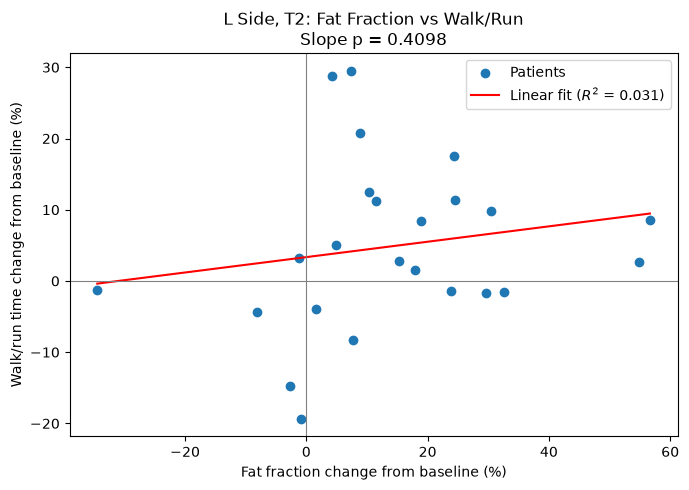

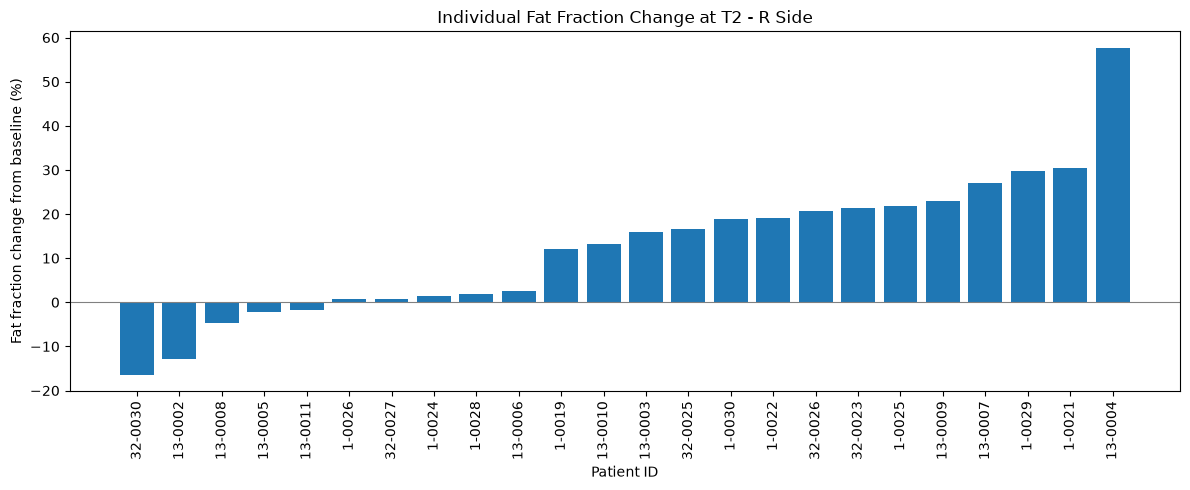

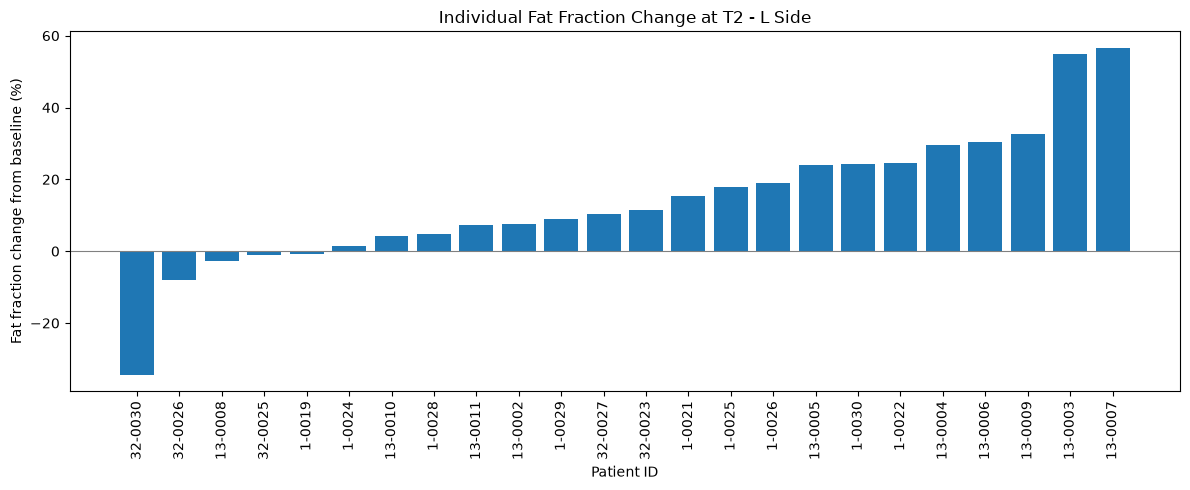

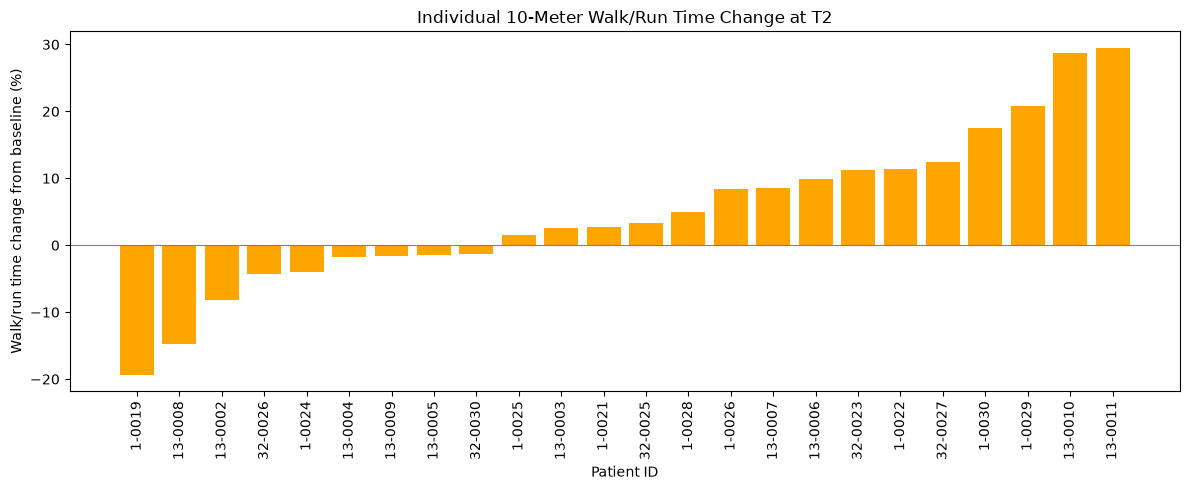

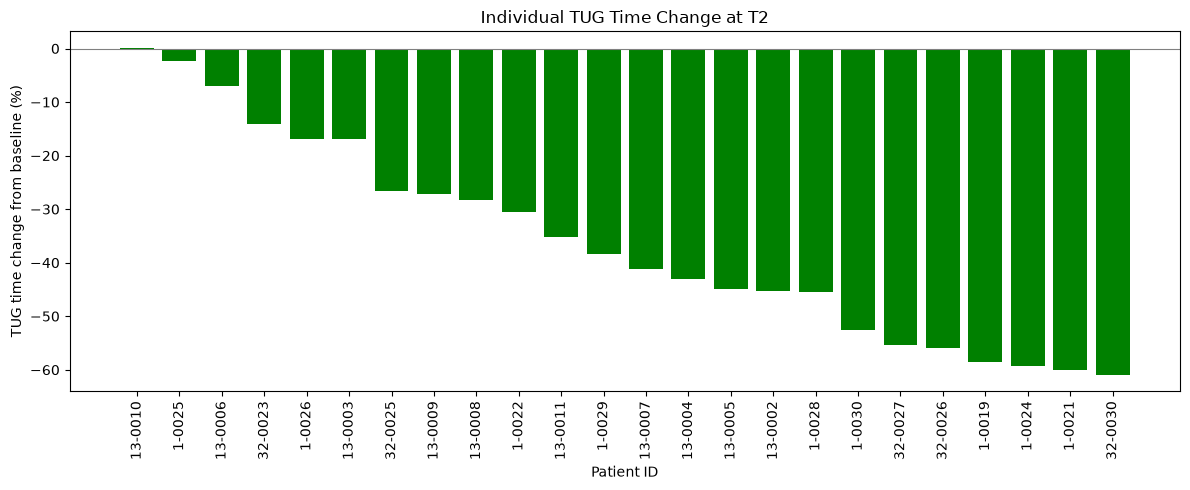

In [13]:

# Individual patient bar graphs 
out = os.path.join(os.path.dirname(path), 'FSHD_Results')
os.makedirs(out, exist_ok=True)

for side in ['R', 'L']:
    for t in ['T1', 'T2']:
        df[f'pct_{side}_{t}'] = (
            (df[f'ff_{t}_{side}'] - df[f'ff_baseline_{side}'])
            / df[f'ff_baseline_{side}'] * 100
        )

for i, r in df.iterrows():
    fig, ax = plt.subplots()
    x = np.arange(2)
    ax.bar(x - .2, [r.pct_R_T1, r.pct_R_T2], .4, label='Right')
    ax.bar(x + .2, [r.pct_L_T1, r.pct_L_T2], .4, label='Left')
    ax.axhline(0, color='gray')
    ax.set_xticks(x, [f'T1 ({T1:.1f} mo)', f'T2 ({T2:.1f} mo)'])
    ax.set_ylabel('Fat fraction change (%)')
    ax.set_title(f'Patient {r.get("patient_id", i)}')
    ax.legend()
    fig.tight_layout()
    fig.savefig(f'{out}/patient_{i}.png')
    plt.close(fig)


# Statistical significance: change from baseline and between time points
for side in ['R', 'L']:
    for t in ['T1', 'T2']:
        x = df[f'pct_{side}_{t}'].dropna()
        if len(x) >= 2:
            print(side, t, 'change vs baseline:',
                  stats.ttest_1samp(x, 0))

    pair = df[[f'pct_{side}_T1', f'pct_{side}_T2']].dropna()
    if len(pair) >= 3:
        print(side, 'T1 vs T2:',
              stats.ttest_rel(pair.iloc[:, 0], pair.iloc[:, 1]))


# Calculate percent change in 10-meter walk/run time
for t in ['T1', 'T2']:
    df[f'wr_pct_{t}'] = (
        (df[f'wr_10_{t}'] - df['wr_10_baseline'])
        / df['wr_10_baseline'] * 100
    )

# Linear regression, statistical significance, and scatter plots
for side in ['R', 'L']:
    for t in ['T1', 'T2']:
        pair = df[[f'pct_{side}_{t}', f'wr_pct_{t}']].dropna()

        if len(pair) >= 3:
            x = pair[f'pct_{side}_{t}'].to_numpy()
            y = pair[f'wr_pct_{t}'].to_numpy()

            # Linear regression
            slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

            print(f'\n{side} side, {t}')
            print(f'N = {len(pair)}')
            print(f'Equation: y = {slope:.4f}x + {intercept:.4f}')
            print(f'R-squared = {r_value**2:.4f}')
            print(f'Slope p-value = {p_value:.4f}')
            print(f'Pearson r = {r_value:.4f}')

            # Plot data and regression line
            fig, ax = plt.subplots(figsize=(7, 5))
            ax.scatter(x, y, label='Patients')

            line_x = np.linspace(x.min(), x.max(), 100)
            ax.plot(
                line_x,
                slope * line_x + intercept,
                color='red',
                label=f'Linear fit ($R^2$ = {r_value**2:.3f})'
            )

            ax.axhline(0, color='gray', linewidth=0.8)
            ax.axvline(0, color='gray', linewidth=0.8)
            ax.set_xlabel('Fat fraction change from baseline (%)')
            ax.set_ylabel('Walk/run time change from baseline (%)')
            ax.set_title(
                f'{side} Side, {t}: Fat Fraction vs Walk/Run\n'
                f'Slope p = {p_value:.4f}'
            )
            ax.legend()
            fig.tight_layout()
            fig.savefig(f'{out}/correlation_{side}_{t}.png')
            plt.show()

# Individual patient percent change from baseline to T2

# Fat fraction: one bar per patient for each side at T2
for side in ['R', 'L']:
    values = df[f'pct_{side}_T2'].dropna().sort_values()
    subjects = df.loc[values.index, 'subject_id'].astype(str)

    plt.figure(figsize=(12, 5))
    plt.bar(subjects, values)
    plt.axhline(0, color='gray', linewidth=0.8)
    plt.xlabel('Patient ID')
    plt.ylabel('Fat fraction change from baseline (%)')
    plt.title(f'Individual Fat Fraction Change at T2 - {side} Side')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.savefig(f'{out}/individual_fat_fraction_T2_{side}.png')
    plt.show()


# Walk/run time: one bar per patient at T2
values = df['wr_pct_T2'].dropna().sort_values()
subjects = df.loc[values.index, 'subject_id'].astype(str)

plt.figure(figsize=(12, 5))
plt.bar(subjects, values, color='orange')
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlabel('Patient ID')
plt.ylabel('Walk/run time change from baseline (%)')
plt.title('Individual 10-Meter Walk/Run Time Change at T2')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(f'{out}/individual_walk_run_T2.png')
plt.show()

# Calculate TUG time percent change from baseline
df['tug_pct_T2'] = (
    (df['tug_time_T2'] - df['tug_time_baseline'])
    / df['tug_time_baseline'] * 100
)

# Individual patient TUG graph, sorted lowest to highest
values = df.loc[df['tug_pct_T2'].notna(), 'tug_pct_T2']
values = values.loc[values.abs().sort_values().index]
subjects = df.loc[values.index, 'subject_id'].astype(str)

x = np.arange(len(values))

plt.figure(figsize=(12, 5))
plt.bar(x, values, color='green')


plt.axhline(0, color='gray', linewidth=0.8)
plt.xticks(x, subjects, rotation=90)
plt.xlabel('Patient ID')
plt.ylabel('TUG time change from baseline (%)')
plt.title('Individual TUG Time Change at T2')
plt.tight_layout()
plt.savefig(f'{out}/individual_tug_T2.png')
plt.show()

In [14]:
# Summary of the results above: mean change from baseline, spread, and significance
rows = []
for label, cols in [('Fat fraction, right TA', ('pct_R_T1', 'pct_R_T2')),
                    ('Fat fraction, left TA', ('pct_L_T1', 'pct_L_T2')),
                    ('10 m walk/run time', ('wr_pct_T1', 'wr_pct_T2'))]:
    for t, c in zip(['T1', 'T2'], cols):
        x = df[c]
        rows.append({'measure': label, 'time point': t, 'n': len(x),
                     'mean % change': x.mean(), 'SD': x.std(),
                     'p (vs 0)': stats.ttest_1samp(x, 0).pvalue})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Fat fraction change in percentage points per year, to compare with published values
print()
for side in ['R', 'L']:
    for t, T in [('T1', T1), ('T2', T2)]:
        pts_per_year = (df[f'ff_{t}_{side}'] - df[f'ff_baseline_{side}']) / (T / 12)
        print(f'{side} side, baseline to {t}: mean {pts_per_year.mean():.2f} percentage points per year')

# Baseline (cross-sectional) relationship between fat fraction and function, all patients
full = pd.read_csv(path)
full['ff_baseline_mean'] = full[['ff_baseline_R', 'ff_baseline_L']].mean(axis=1)
print()
for col in ['wr_10_baseline', 'tug_time_baseline', 'ascend_4_baseline',
            'clinical_severity_score_baseline', 'dorsiflexion_qmt_R_baseline']:
    pair = full[['ff_baseline_mean', col]].dropna()
    rho, p = stats.spearmanr(pair['ff_baseline_mean'], pair[col])
    print(f'Baseline fat fraction vs {col}: n = {len(pair)}, Spearman rho = {rho:.2f}, p = {p:.5f}')

               measure time point  n  mean % change     SD  p (vs 0)
Fat fraction, right TA         T1 24          7.699 16.763     0.034
Fat fraction, right TA         T2 24         12.394 16.344     0.001
 Fat fraction, left TA         T1 24         10.487 11.659     0.000
 Fat fraction, left TA         T2 24         14.089 19.489     0.002
    10 m walk/run time         T1 24          3.843 10.576     0.088
    10 m walk/run time         T2 24          4.868 11.938     0.058

R side, baseline to T1: mean 0.83 percentage points per year
R side, baseline to T2: mean 0.83 percentage points per year
L side, baseline to T1: mean 1.72 percentage points per year
L side, baseline to T2: mean 1.26 percentage points per year

Baseline fat fraction vs wr_10_baseline: n = 34, Spearman rho = 0.67, p = 0.00002
Baseline fat fraction vs tug_time_baseline: n = 34, Spearman rho = 0.59, p = 0.00028
Baseline fat fraction vs ascend_4_baseline: n = 34, Spearman rho = 0.60, p = 0.00019
Baseline fat fracti

The code above converts the interpolated values at T1 (11.15 months) and T2 (22.13 months) into percent change from each patient's baseline, tests whether those changes differ from zero, and checks whether fat fraction change lines up with walk/run change. The summary cell below the plots collects the numbers for the 24 patients with complete data. Fat fraction in the tibialis anterior increased significantly from baseline on both legs at both time points (p from 0.0002 to 0.034), with mean increases of 7.7% (right) and 10.5% (left) at T1 and 12.4% (right) and 14.1% (left) at T2. These are relative changes, and in absolute terms they work out to roughly 1 to 2 percentage points of fat fraction per year. The change from T1 to T2 was not significant on either side (right p = 0.074, left p = 0.297), which suggests that most of the measurable increase had already appeared by about 11 months, although with only 24 patients we cannot say this with confidence. Walk/run time got slower on average by 3.8% at T1 and 4.9% at T2, but neither change was statistically significant (p = 0.088 and p = 0.058). The scatter plots show no meaningful relationship between percent change in fat fraction and percent change in walk/run time (all R-squared values are below 0.06 and slope p-values range from 0.27 to 0.79). We can conclude that fat fraction changed more consistently than walk/run time over this period, but that patients who gained more fat did not reliably become slower. At baseline, however, patients with higher fat fraction clearly had worse function across all 34 patients (for example Spearman rho = 0.67 with walk/run time and 0.70 with clinical severity score), so fat fraction reflects how affected a patient is even though its short-term change does not yet track function. The individual patient bar graphs also show wide differences between patients, with some patients decreasing in fat fraction, which is likely measurement noise or interpolation error since fat is not expected to be lost.

## Conclusions:

Our analysis suggests that MRI fat fraction of the tibialis anterior is a more consistent marker of FSHD progression than the functional tests. Fat fraction rose significantly from baseline on both legs at both interpolated time points (11.15 and 22.13 months), while 10-meter walk/run time showed only a non-significant trend toward slower times (p = 0.088 and p = 0.058). Fat fraction change was not significantly related to walk/run change, so patients who gained more fat were not reliably the ones who slowed down.

Validation against other studies. This agrees with published cohorts, where MRI changes over one to two years while function does not (Fatehi et al., 2017; Wang et al., 2021b), and clinical outcomes change significantly only over about 5 years (Vincenten et al., 2023). Our gain of roughly 1 to 2 percentage points per year falls within the 1.0% to 6.7% yearly range that Vincenten et al. (2023) summarize. Our baseline results also match Mul et al. (2017), who found that leg fat fraction correlated strongly with the 6-minute walk test (-0.701). In our 34 patients, baseline fat fraction correlated with walk/run time (rho = 0.67) and clinical severity score (rho = 0.70). One difference is that Wang et al. (2021b) saw little tibialis anterior change over 12 months, likely because we report relative change and used interpolated time points.

Use as an endpoint. Fat fraction is the strongest candidate exploratory endpoint because it is quantitative, changes within about a year, and tracks severity, while functional tests are better used as supporting measures. Before using it to judge a treatment, we would need test-retest reliability across scanners, a threshold for meaningful change (LoRusso et al., 2019), a larger cohort, and a control group.

Ethical implications. Fat fraction alone could favor drugs that slow fat replacement without helping patients function better, while functional tests reflect patient experience but exclude those who can no longer walk (about 20% of people with FSHD need a wheelchair before 50; FSHD Society, 2025). MRI is objective but costly and less accessible. We therefore recommend fat fraction alongside at least one patient-relevant functional or strength measure.

## Limitations and Future Work:

One limitation of our work was the relatively small sample population; out of all the patients in the trial, only 24 of them had data for all functional and biomarker tests at the three appointments. This limited our statistical power and increased the impact of outliers and variance across individuals. Additionally, since patients visited for follow-ups at a scattering of points, we had to interpolate results which meant we were using estimates for data values at the chosen time points. Functional tests such as the 10-meter walk/run and TUG tests have proven to be inaccurate predictors of clinical regression and of a patient's progression with the disease. Patients have noted, as well as researchers, that functional tests are nuanced due to factors such as compensation with other muscle groups, daily fluctuations in energy/chronic pain, and motivation. With more time and access to a larger and more controlled data set, we would test more isolated/specific functional tests, like those along the lines of the dorsiflexion strength, as those could be better indicators of one muscle's state. Additionally, using fat fraction measurements in tandem with functional tests could provide a more accurate picture. 

## AI Usage Statement:

Claude was used to assist in analysis in the results shown by the figures and tables, which helped write the conclusions by ourselves. Claude was also used to research studies to validate our results, the sources were then checked by us.

## GitHub Repository Link:

https://github.com/artyrchuk/BME_2315_Module2.git

## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

Fatehi, F., Salort-Campana, E., Le Troter, A., Lareau-Trudel, E., Bydder, M., Fouré, A., et al. (2017). Long-term follow-up of MRI changes in thigh muscles of patients with facioscapulohumeral dystrophy: A quantitative study. PLoS ONE, 12(8), e0183825. https://doi.org/10.1371/journal.pone.0183825

LoRusso, S., Johnson, N. E., McDermott, M. P., Eichinger, K., Butterfield, R. J., Carraro, E., Higgs, K., Lewis, L., Mul, K., Sacconi, S., Sansone, V. A., Shieh, P., van Engelen, B., Wagner, K., Wang, L., Statland, J. M., & Tawil, R. (2019). Clinical trial readiness to solve barriers to drug development in FSHD (ReSolve): protocol of a large, international, multi-center prospective study. BMC Neurology, 19(1), 224. https://pmc.ncbi.nlm.nih.gov/articles/PMC6734593

Mul, K., Vincenten, S. C. C., Voermans, N. C., Lemmers, R. J. L. F., van der Vliet, P. J., van der Maarel, S. M., Padberg, G. W., Horlings, C. G. C., & van Engelen, B. G. M. (2017). Adding quantitative muscle MRI to the FSHD clinical trial toolbox. Neurology, 89(20), 2057–2065. https://doi.org/10.1212/WNL.0000000000004647

Statland, J. M., & Tawil, R. (2016). Facioscapulohumeral muscular dystrophy. Continuum, 22(6), 1916–1931. https://doi.org/10.1212/con.0000000000000399

Understanding FSHD - FSHD society. FSHD Society - Empowering FSHD Patients, Accelerating FSHD Progress. (2025, April 18). https://www.fshdsociety.org/living-with-fshd/understanding-fshd/

Vincenten, S. C. C., Mul, K., van As, D., Jansen, J. J., Heskamp, L., Heerschap, A., van Engelen, B. G. M., & Voermans, N. C. (2023). Five-year follow-up study on quantitative muscle magnetic resonance imaging in facioscapulohumeral muscular dystrophy: The link to clinical outcome. Journal of Cachexia, Sarcopenia and Muscle. https://pmc.ncbi.nlm.nih.gov/articles/PMC10401523

Wang, L. H., Shaw, D. W. W., Faino, A., Budech, C. B., Lewis, L. M., Statland, J., Eichinger, K., Tapscott, S. J., Tawil, R. N., & Friedman, S. D. (2021b). Longitudinal study of MRI and functional outcome measures in facioscapulohumeral muscular dystrophy. BMC Musculoskeletal Disorders, 22, 262. https://doi.org/10.1186/s12891-021-04134-7


Wong, C. J., Friedman, S. D., Snider, L., Bennett, S. R., Jones, T. I., Jones, P. L., Shaw, D. W. W., Blemker, S. S., Riem, L., DuCharme, O., Lemmers, R. J. F. L., van der Maarel, S. M., Wang, L. H., Tawil, R., Statland, J. M., & Tapscott, S. J. (2024). Regional and bilateral MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression. Human molecular genetics, 33(8), 698–708. https://doi.org/10.1093/hmg/ddae007


## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*